In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df[["Time", "Amount", "Class"]].describe()

(284807, 31)
Missing values: 0
Duplicate rows: 1081


,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


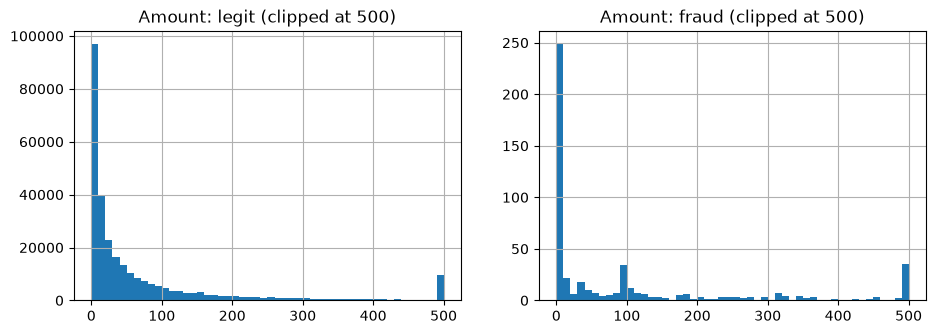

In [2]:
counts = df["Class"].value_counts()
print(counts)
print(f"Fraud rate: {df['Class'].mean():.4%}")
print(df.groupby("Class")["Amount"].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.loc[df.Class == 0, "Amount"].clip(upper=500).hist(bins=50, ax=ax[0]); ax[0].set_title("Amount: legit (clipped at 500)")
df.loc[df.Class == 1, "Amount"].clip(upper=500).hist(bins=50, ax=ax[1]); ax[1].set_title("Amount: fraud (clipped at 500)")
plt.show()

In [3]:
df = df.sort_values("Time").reset_index(drop=True)
n = len(df)
i1, i2 = int(n * 0.70), int(n * 0.85)
train, val, test = df.iloc[:i1], df.iloc[i1:i2], df.iloc[i2:]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} rows={len(part):7d} frauds={part.Class.sum():4d} rate={part.Class.mean():.4%}")

features = [c for c in df.columns if c not in ("Time", "Class")]
X_train, y_train = train[features], train["Class"]
X_val, y_val = val[features], val["Class"]

train rows= 199364 frauds= 384 rate=0.1926%
val   rows=  42721 frauds=  56 rate=0.1311%
test  rows=  42722 frauds=  52 rate=0.1217%


In [4]:
import os
os.makedirs("../data/processed", exist_ok=True)
train.to_parquet("../data/processed/train.parquet")
val.to_parquet("../data/processed/val.parquet")
test.to_parquet("../data/processed/test.parquet")

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

base = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
base.fit(X_train, y_train)
p = base.predict_proba(X_val)[:, 1]

print(f"Random-guess PR-AUC (= fraud rate): {y_val.mean():.4f}")
print(f"Baseline PR-AUC : {average_precision_score(y_val, p):.4f}")
print(f"Baseline ROC-AUC: {roc_auc_score(y_val, p):.4f}")
print(classification_report(y_val, (p >= 0.5).astype(int), digits=3))

Random-guess PR-AUC (= fraud rate): 0.0013
Baseline PR-AUC : 0.8397
Baseline ROC-AUC: 0.9815
              precision    recall  f1-score   support

           0      1.000     0.971     0.985     42665
           1      0.040     0.929     0.076        56

    accuracy                          0.970     42721
   macro avg      0.520     0.950     0.531     42721
weighted avg      0.999     0.970     0.984     42721

